# 02 – Exploratory Data Analysis: Patient Trends

**Input:** `data/processed/cleaned_data.csv` (made by `01_data_cleaning.ipynb`): one first hospital stay per patient, 69,970 patients.

**Main question:** which patients are readmitted to hospital within 30 days?

**A note on wording:** this is observational data, so every finding below is a **pattern** (two things happen together), not proof that one **causes** the other.

Charts are also saved to `reports/figures/` for the README and the dashboard.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter

# The project folder is one level above notebooks/
PROJECT_DIR = Path.cwd().parent
sys.path.append(str(PROJECT_DIR))
from src.icd9 import icd9_category

FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

### Chart style

One consistent, quiet style for every chart:
- **One blue** for every bar, because each chart shows a single measure. Using a different colour per bar would suggest the colours mean something.
- **Light gridlines and grey text**, so the data stands out.
- A **grey reference line** for the overall readmission rate, so each group can be compared with the average.

In [2]:
BLUE = "#2a78d6"        # main colour for bars
TEXT = "#0b0b0b"        # titles
TEXT_SOFT = "#52514e"   # axis labels
MUTED = "#898781"       # reference lines
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines
BACKGROUND = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": BACKGROUND,
    "axes.facecolor": BACKGROUND,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": TEXT_SOFT,
    "axes.titlecolor": TEXT,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,      # gridlines behind the bars
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": TEXT_SOFT,
    "ytick.color": TEXT_SOFT,
    "font.size": 10,
    "figure.dpi": 110,
})


def save(fig, name):
    """Save a chart to reports/figures/ as a PNG."""
    fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

## Load the cleaned data

In [3]:
df = pd.read_csv(PROJECT_DIR / "data" / "processed" / "cleaned_data.csv", low_memory=False)

# 1 = readmitted within 30 days, 0 = not. The average of a 0/1 column is a rate.
df["readmit_flag"] = (df["readmitted_30days"] == "Yes").astype(int)

overall_rate = df["readmit_flag"].mean()
print(f"{len(df):,} patients, {df.shape[1]} columns")

69,970 patients, 51 columns


In [4]:
def rate_table(data, group_col, order=None):
    """Readmission rate and patient count for each group in group_col."""
    table = data.groupby(group_col, observed=True).agg(
        patients=("readmit_flag", "size"),
        readmission_rate=("readmit_flag", "mean"),
    )
    if order is not None:
        table = table.reindex(order)
    return table


def rate_bar_chart(ax, table, title, xlabel):
    """Bar chart of readmission rate per group, with the overall rate as a grey line."""
    labels = table.index.astype(str)
    ax.bar(labels, table["readmission_rate"], color=BLUE, width=0.7)
    ax.axhline(overall_rate, color=MUTED, linewidth=1.2)
    # Label the line just outside the right edge of the chart, so it never covers a bar.
    # get_yaxis_transform(): x is a fraction of the chart width, y is a data value.
    ax.text(1.01, overall_rate, f"overall\n{overall_rate:.1%}", transform=ax.get_yaxis_transform(),
            color=MUTED, va="center", ha="left", fontsize=9)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("30-day readmission rate")
    ax.grid(axis="x", visible=False)

## 1. Patient demographics

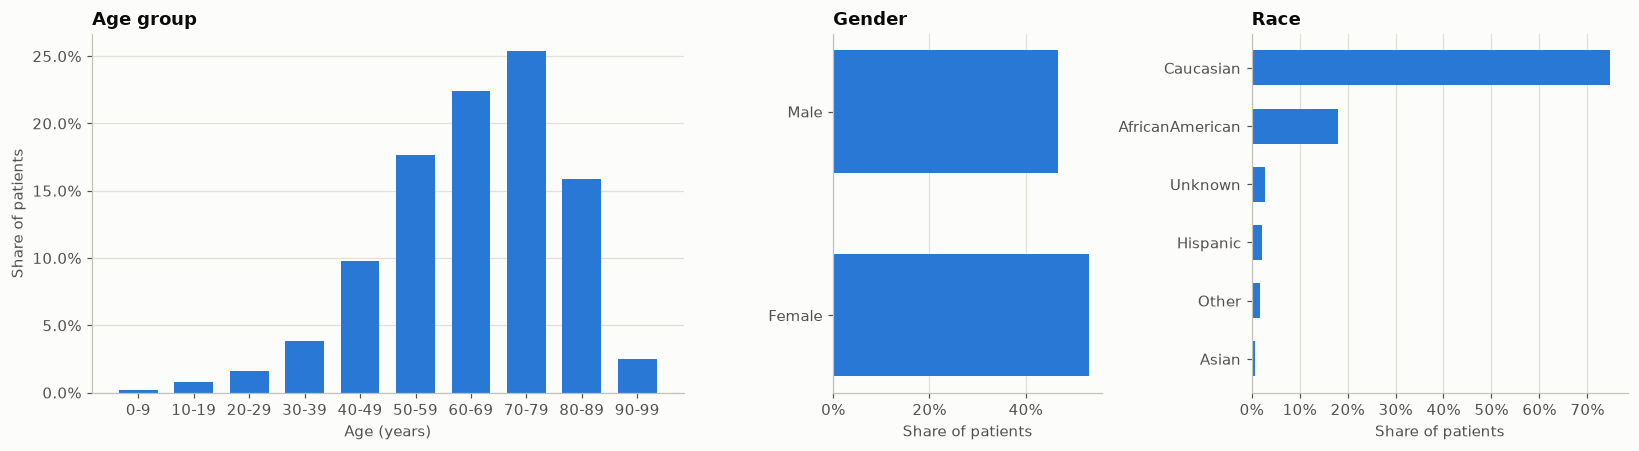

In [5]:
age_order = sorted(df["age_group"].unique(), key=lambda g: int(g.split("-")[0]))

age_share = df["age_group"].value_counts(normalize=True).reindex(age_order)
gender_share = df["gender"].value_counts(normalize=True)
race_share = df["race"].value_counts(normalize=True).sort_values()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [2.2, 1, 1.4]})

axes[0].bar(age_share.index, age_share.values, color=BLUE, width=0.7)
axes[0].set_title("Age group")
axes[0].set_xlabel("Age (years)")
axes[0].grid(axis="x", visible=False)

axes[1].barh(gender_share.index, gender_share.values, color=BLUE, height=0.6)
axes[1].set_title("Gender")
axes[1].grid(axis="y", visible=False)

axes[2].barh(race_share.index, race_share.values, color=BLUE, height=0.6)
axes[2].set_title("Race")
axes[2].grid(axis="y", visible=False)

axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].set_ylabel("Share of patients")
for ax in axes[1:]:
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_xlabel("Share of patients")

fig.tight_layout()
save(fig, "01_demographics")
plt.show()

In [6]:
# The same numbers as a table
pd.concat(
    {"age_group": age_share, "gender": gender_share, "race": race_share.sort_values(ascending=False)}
).mul(100).round(1).rename("percent").to_frame()

percent
age_group 0-9                  0.2
          10-19                0.8
          20-29                1.6
          30-39                3.8
          40-49                9.8
          50-59               17.6
          60-69               22.4
          70-79               25.4
          80-89               15.9
          90-99                2.5
gender    Female              53.2
          Male                46.8
race      Caucasian           74.7
          AfricanAmerican     18.0
          Unknown              2.7
          Hispanic             2.1
          Other                1.6
          Asian                0.7

**What the numbers show:** most patients are older: **two in three are 60 or above**, and the largest group is 70–79 (25%). Slightly more patients are female (53%), and most are Caucasian (75%), followed by African American (18%).

## 2. Length of stay

In [7]:
df["length_of_stay"].describe().round(2)

count    69970.00
mean         4.27
std          2.93
min          1.00
25%          2.00
50%          3.00
75%          6.00
max         14.00
Name: length_of_stay, dtype: float64

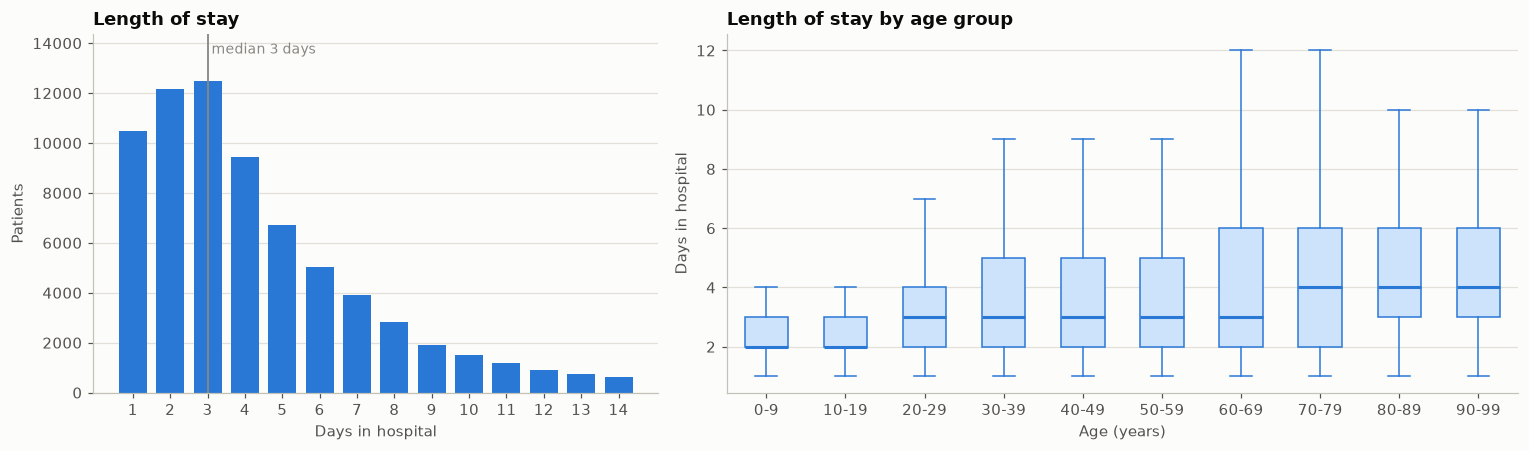

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 1.4]})

# Left: how many patients stayed 1, 2, 3 ... 14 days
stay_counts = df["length_of_stay"].value_counts().sort_index()
axes[0].bar(stay_counts.index, stay_counts.values, color=BLUE, width=0.75)
axes[0].axvline(df["length_of_stay"].median(), color=MUTED, linewidth=1.2)
axes[0].set_ylim(0, stay_counts.max() * 1.15)   # leave room above the bars for the label
axes[0].text(df["length_of_stay"].median(), stay_counts.max() * 1.1,
             f" median {df['length_of_stay'].median():.0f} days", color=MUTED, va="center", fontsize=9)
axes[0].set_xticks(range(1, 15))
axes[0].set_title("Length of stay")
axes[0].set_xlabel("Days in hospital")
axes[0].set_ylabel("Patients")
axes[0].grid(axis="x", visible=False)

# Right: one box per age group. The line in the box is the median;
# the box covers the middle 50% of patients.
groups = [df.loc[df["age_group"] == g, "length_of_stay"] for g in age_order]
axes[1].boxplot(
    groups, tick_labels=age_order, widths=0.55, patch_artist=True, showfliers=False,
    boxprops={"facecolor": "#cde2fb", "edgecolor": BLUE},
    medianprops={"color": BLUE, "linewidth": 2},
    whiskerprops={"color": BLUE}, capprops={"color": BLUE},
)
axes[1].set_title("Length of stay by age group")
axes[1].set_xlabel("Age (years)")
axes[1].set_ylabel("Days in hospital")
axes[1].grid(axis="x", visible=False)

fig.tight_layout()
save(fig, "02_length_of_stay")
plt.show()

In [9]:
df.groupby("age_group")["length_of_stay"].agg(["median", "mean", "count"]).reindex(age_order).round(2)

,median,mean,count
age_group,,,
0-9,2.0,2.57,153
10-19,2.0,2.87,534
20-29,3.0,3.46,1121
30-39,3.0,3.63,2692
40-49,3.0,3.85,6828
50-59,3.0,3.97,12349
60-69,3.0,4.24,15683
70-79,4.0,4.51,17748
80-89,4.0,4.78,11102


**What the numbers show:** a typical stay is short (**median 3 days**, average 4.3). The distribution is right-skewed: most stays last 1–4 days and a smaller group stays up to 14. Older patients tend to stay longer: the median rises from 2 days for patients under 20 to 4 days for patients aged 70 and over.

## 3. Readmission within 30 days

In [10]:
print(f"Overall 30-day readmission rate: {overall_rate:.1%}")
print(f"({df['readmit_flag'].sum():,} of {len(df):,} patients)")

Overall 30-day readmission rate: 9.0%
(6,277 of 69,970 patients)


**What the numbers show:** about **9.0%** of patients (6,277 of 69,970) were readmitted within 30 days of their first recorded stay. This is the baseline that every group below is compared against (the grey line).

Before plotting, we group two numeric columns into ranges so each bar has enough patients:
- `num_medications` → ranges like 1–5, 6–10, …
- `number_inpatient` (hospital stays in the year **before** this visit) → 0, 1, 2, 3, 4, 5+

Admission types with fewer than 100 patients (*Newborn*: 9, *Trauma Center*: 18) are left out of the chart. With so few patients, their rates would swing wildly from one or two cases.

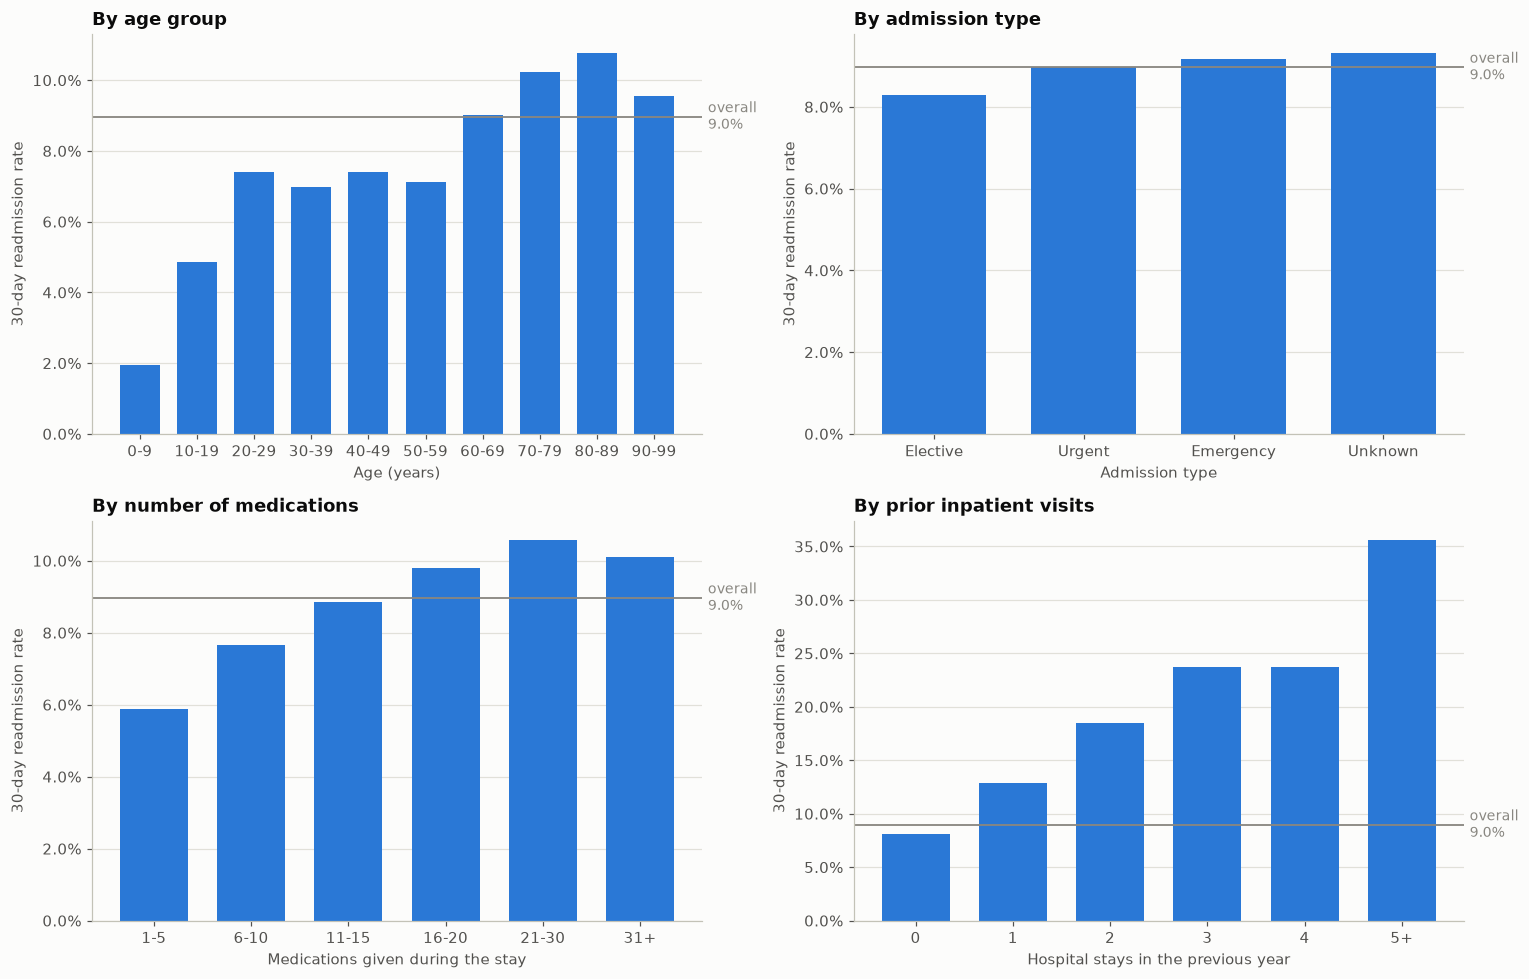

In [11]:
df["medication_range"] = pd.cut(
    df["num_medications"],
    bins=[0, 5, 10, 15, 20, 30, np.inf],
    labels=["1-5", "6-10", "11-15", "16-20", "21-30", "31+"],
)

# clip(upper=5) turns every value above 5 into 5, which we label "5+"
df["prior_inpatient"] = df["number_inpatient"].clip(upper=5).astype(str).replace("5", "5+")

by_age = rate_table(df, "age_group", age_order)
by_admission = rate_table(df, "admission_type_label")
by_admission = by_admission[by_admission["patients"] >= 100].sort_values("readmission_rate")
by_meds = rate_table(df, "medication_range")
by_inpatient = rate_table(df, "prior_inpatient", ["0", "1", "2", "3", "4", "5+"])

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
rate_bar_chart(axes[0, 0], by_age, "By age group", "Age (years)")
rate_bar_chart(axes[0, 1], by_admission, "By admission type", "Admission type")
rate_bar_chart(axes[1, 0], by_meds, "By number of medications", "Medications given during the stay")
rate_bar_chart(axes[1, 1], by_inpatient, "By prior inpatient visits", "Hospital stays in the previous year")

fig.tight_layout()
save(fig, "03_readmission_rates")
plt.show()

In [12]:
# The same numbers as tables
for name, table in [("Age group", by_age), ("Admission type", by_admission),
                    ("Medications", by_meds), ("Prior inpatient visits", by_inpatient)]:
    print(name)
    print(table.assign(readmission_rate=table["readmission_rate"].mul(100).round(1)).to_string(), "\n")

Age group
           patients  readmission_rate
age_group                            
0-9             153               2.0
10-19           534               4.9
20-29          1121               7.4
30-39          2692               7.0
40-49          6828               7.4
50-59         12349               7.1
60-69         15683               9.0
70-79         17748              10.2
80-89         11102              10.8
90-99          1760               9.5 

Admission type
                      patients  readmission_rate
admission_type_label                            
Elective                 13784               8.3
Urgent                   12802               9.0
Emergency                35464               9.2
Unknown                   7893               9.3 

Medications
                  patients  readmission_rate
medication_range                            
1-5                   4054               5.9
6-10                 15440               7.7
11-15                20253   

**What the numbers show:**
- **Age:** the rate is around 7% for most patients under 60 and rises to about 10–11% for ages 70–89.
- **Admission type:** the rates are close together (about 8–9%). Elective (planned) admissions are slightly lower than emergency ones.
- **Medications:** patients given more medications are readmitted more often, from 5.9% (1–5 medications) to about 10–11% (21+).
- **Prior inpatient visits:** this shows the strongest pattern. The rate climbs steadily from **8.1%** with no hospital stay in the previous year to **35.6%** with five or more.

## 4. Diagnoses

`diag_1` is the **primary diagnosis**: the main reason for the hospital stay. It is an ICD-9 code (for example `428` = heart failure). There are hundreds of different codes, which is too many to compare. So `src/icd9.py` groups them into broad body-system categories using the official ICD-9 code ranges, with diabetes (`250.xx`) as its own category.

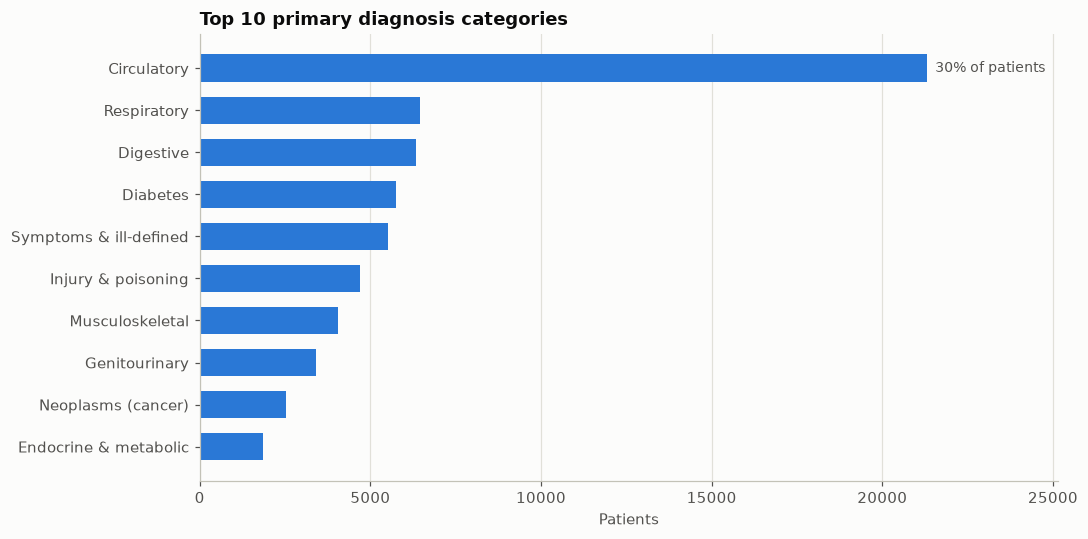

In [13]:
df["diagnosis_category"] = df["diag_1"].map(icd9_category)

diagnoses = rate_table(df, "diagnosis_category")
diagnoses["share"] = diagnoses["patients"] / len(df)
top10 = diagnoses.sort_values("patients", ascending=False).head(10)

fig, ax = plt.subplots(figsize=(10, 5))
plot_data = top10.sort_values("patients")          # biggest bar at the top
ax.barh(plot_data.index, plot_data["patients"], color=BLUE, height=0.65)
ax.set_title("Top 10 primary diagnosis categories")
ax.set_xlabel("Patients")
ax.grid(axis="y", visible=False)

# Label only the largest bar, to show how far ahead it is
biggest = top10.iloc[0]
ax.text(biggest["patients"], len(plot_data) - 1, f"  {biggest['share']:.0%} of patients",
        va="center", color=TEXT_SOFT, fontsize=9)
ax.set_xlim(0, biggest["patients"] * 1.18)

fig.tight_layout()
save(fig, "04_top_diagnoses")
plt.show()

In [14]:
top10.assign(
    share=top10["share"].mul(100).round(1),
    readmission_rate=top10["readmission_rate"].mul(100).round(1),
)

,patients,readmission_rate,share
diagnosis_category,,,
Circulatory,21315,9.7,30.5
Respiratory,6446,8.3,9.2
Digestive,6325,7.9,9.0
Diabetes,5748,9.1,8.2
Symptoms & ill-defined,5503,6.3,7.9
Injury & poisoning,4692,10.8,6.7
Musculoskeletal,4064,8.4,5.8
Genitourinary,3414,9.0,4.9
Neoplasms (cancer),2538,9.1,3.6


**What the numbers show:** **circulatory** conditions (heart and blood vessels) are by far the most common main diagnosis (about 30% of patients), more than three times the next category, respiratory (9%). Only about 8% of patients were admitted mainly *for* diabetes; most patients have diabetes alongside the condition they were admitted with. Readmission rates among the top 10 range from about 6% (symptoms & ill-defined) to about 11% (injury & poisoning).

## 5. Medications

Each medication column records what happened to that drug during the stay: `No` (not prescribed), `Steady` (kept the same dose), `Up` (dose increased) or `Down` (dose decreased). The `change` column is `Ch` if **any** diabetes medication was changed.

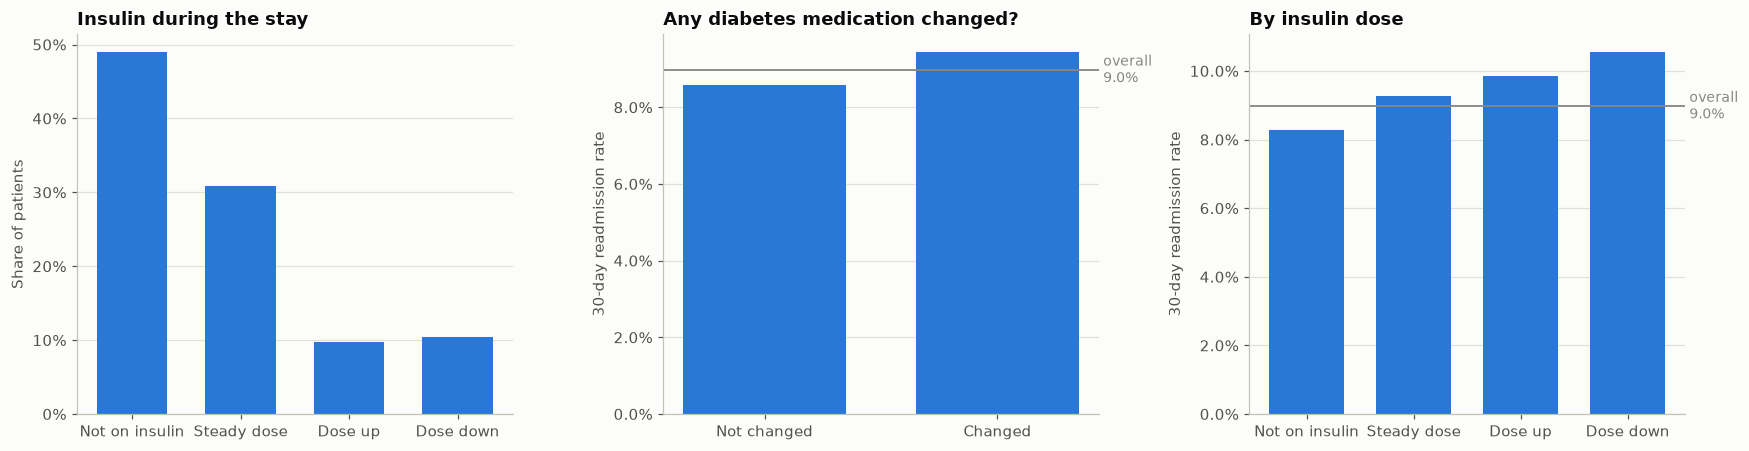

In [15]:
# Readable names for the insulin values, used in both insulin charts
insulin_names = {"No": "Not on insulin", "Steady": "Steady dose", "Up": "Dose up", "Down": "Dose down"}
df["insulin_status"] = df["insulin"].map(insulin_names)
insulin_order = list(insulin_names.values())

insulin_share = df["insulin_status"].value_counts(normalize=True).reindex(insulin_order)

df["medication_change"] = df["change"].map({"Ch": "Changed", "No": "Not changed"})
by_change = rate_table(df, "medication_change", ["Not changed", "Changed"])
by_insulin = rate_table(df, "insulin_status", insulin_order)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

axes[0].bar(insulin_share.index, insulin_share.values, color=BLUE, width=0.65)
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].set_title("Insulin during the stay")
axes[0].set_ylabel("Share of patients")
axes[0].grid(axis="x", visible=False)

rate_bar_chart(axes[1], by_change, "Any diabetes medication changed?", "")
rate_bar_chart(axes[2], by_insulin, "By insulin dose", "")

fig.tight_layout()
save(fig, "05_medications")
plt.show()

In [16]:
print("Insulin (% of patients):")
print(insulin_share.mul(100).round(1).to_string(), "\n")
print(by_change.assign(readmission_rate=by_change["readmission_rate"].mul(100).round(1)).to_string(), "\n")
print(by_insulin.assign(readmission_rate=by_insulin["readmission_rate"].mul(100).round(1)).to_string())

Insulin (% of patients):
insulin_status
Not on insulin    49.0
Steady dose       30.9
Dose up            9.7
Dose down         10.5 

                   patients  readmission_rate
medication_change                            
Not changed           38481               8.6
Changed               31489               9.4 

                patients  readmission_rate
insulin_status                            
Not on insulin     34255               8.3
Steady dose        21617               9.3
Dose up             6777               9.8
Dose down           7321              10.5


**What the numbers show:** about half of patients (51%) received insulin, and the dose was **changed for about 20%** (raised for 10%, lowered for 10%). Patients whose diabetes medication was changed were readmitted slightly more often (9.4% vs 8.6%). The gap is small, and it may simply reflect that patients who needed adjustments were sicker; this data can't tell us which.

## 6. Correlation between numeric columns

**Correlation** measures how strongly two numbers move together, from **−1** (one goes up, the other goes down) through **0** (no straight-line relationship) to **+1** (they go up together).

We leave out `encounter_id`, `patient_nbr` and the `*_id` columns because they are **codes, not quantities**: an admission type of 3 is not "more" than 1. We include `readmit_flag` (1 = readmitted within 30 days) to see which numbers are linked to readmission.

Colour: **blue = positive**, **red = negative**, **grey = close to zero**.

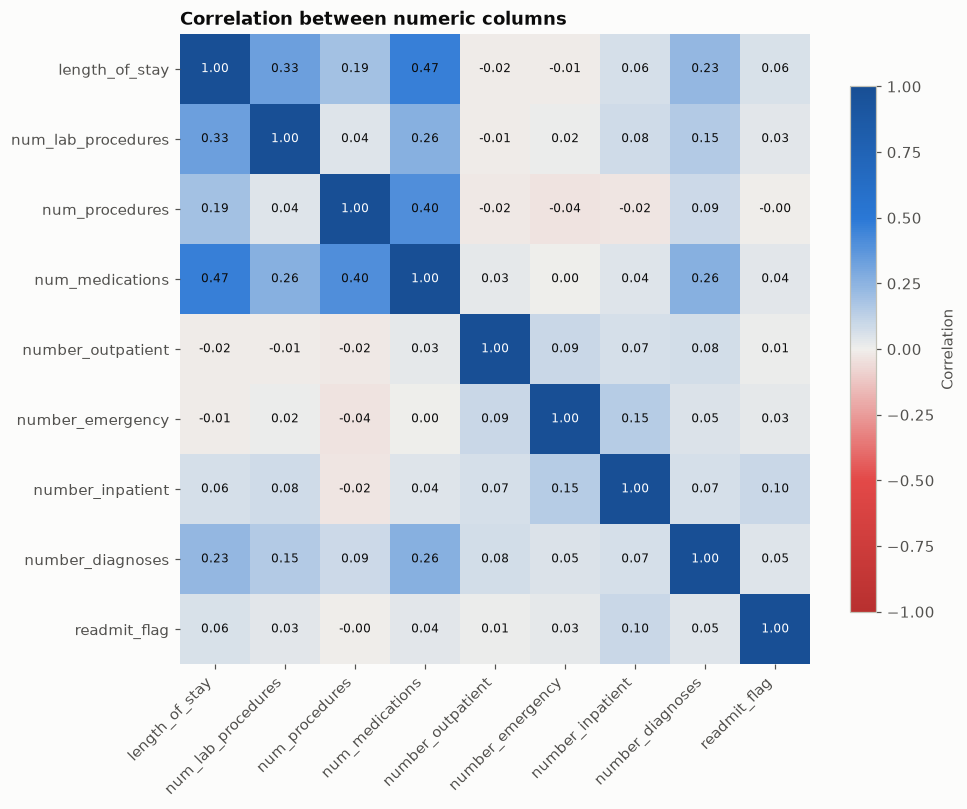

In [17]:
numeric_cols = [
    "length_of_stay", "num_lab_procedures", "num_procedures", "num_medications",
    "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses",
    "readmit_flag",
]
corr = df[numeric_cols].corr()

# Red (negative) -> grey (zero) -> blue (positive)
diverging = LinearSegmentedColormap.from_list("red_grey_blue", ["#b8302f", "#e34948", "#f0efec", "#2a78d6", "#184f95"])

fig, ax = plt.subplots(figsize=(9, 7.5))
image = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_cols)), numeric_cols, rotation=45, ha="right")
ax.set_yticks(range(len(numeric_cols)), numeric_cols)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)

# Write the value in each cell (white text on dark cells so it stays readable)
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        value = corr.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) > 0.6 else TEXT)

fig.colorbar(image, ax=ax, shrink=0.8, label="Correlation")
ax.set_title("Correlation between numeric columns")
fig.tight_layout()
save(fig, "06_correlation_heatmap")
plt.show()

In [18]:
# Which numbers move most with readmission? (sorted, excluding itself)
corr["readmit_flag"].drop("readmit_flag").sort_values(ascending=False).round(3)

number_inpatient      0.100
length_of_stay        0.056
number_diagnoses      0.045
num_medications       0.036
num_lab_procedures    0.032
number_emergency      0.028
number_outpatient     0.009
num_procedures       -0.000
Name: readmit_flag, dtype: float64

**What the numbers show:** the strongest relationships are between measures of **how intensive the stay was**: longer stays go with more medications (0.47) and more lab tests (0.33). Each number on its own is only **weakly** related to readmission (all below 0.11), the largest being prior inpatient visits (0.10). Readmission probably depends on many factors together, not on any single number.

## Summary of patterns

1. Patients are mostly **older** (two-thirds are 60+); stays are **short** (median 3 days) and get longer with age.
2. About **9%** of patients are readmitted within 30 days.
3. The clearest pattern is **prior hospital use**: patients with more inpatient stays in the previous year are readmitted much more often (8% with none, 36% with 5+).
4. Readmission also rises, more gently, with **age** and **number of medications**.
5. **Circulatory** conditions are the most common reason for admission (about 30%).
6. No single numeric column is strongly correlated with readmission.

These are patterns only. The next step is to check whether they still hold when several factors are considered together.